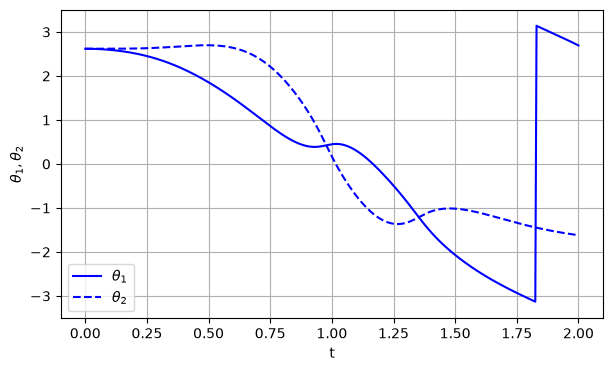

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


def wrap_to_pi(angle):
    return (angle + np.pi) % (2 * np.pi) - np.pi


def dp_ode(t, y, g=9.81, m1=1.0, m2=1.0, L1=1.0, L2=1.0):
    t1, t2, w1, w2 = y
    delta = t1 - t2

    a1 = (L2 / L1) * (m2 / (m1 + m2)) * np.cos(delta)
    a2 = (L1 / L2) * np.cos(delta)

    f1 = -(L2 / L1) * (m2 / (m1 + m2)) * (w2**2) * np.sin(delta) - (g / L1) * np.sin(t1)
    f2 = (L1 / L2) * (w1**2) * np.sin(delta) - (g / L2) * np.sin(t2)

    g1 = (f1 - a1 * f2) / (1 - a1 * a2)
    g2 = (f2 - a2 * f1) / (1 - a1 * a2)
    return [w1, w2, g1, g2]


# Match Steger et al. Fig. 1(c)-(d): T = 2.0 s, h = 0.005, theta_0 = 150 deg
T = 2.0
h = 0.005
t_eval = np.arange(0, T + h, h)
theta0 = np.radians(150)  # 2.6179938779914944 rad

sol = solve_ivp(
    dp_ode,
    t_span=(0, T),
    y0=[theta0, theta0, 0.0, 0.0],
    method="RK45",
    t_eval=t_eval,
    rtol=1e-10,
    atol=1e-12,
)

theta1 = wrap_to_pi(sol.y[0])
theta2 = wrap_to_pi(sol.y[1])

plt.figure(figsize=(7, 4))
plt.plot(sol.t, theta1, color="blue", label="$\\theta_1$")
plt.plot(sol.t, theta2, color="blue", linestyle="--", label="$\\theta_2$")
plt.ylim(-3.5, 3.5)
plt.xlabel("t")
plt.ylabel("$\\theta_1, \\theta_2$")
plt.grid(True)
plt.legend()
plt.savefig("steger_rk45_ref.png", dpi=300)
plt.show()